# Exercício Prático — Classificação de Renda com Árvore de Decisão

**Dataset:** Adult (Census Income)

**Fonte:** [UCI Machine Learning Repository — Adult](https://archive.ics.uci.edu/ml/datasets/adult)

**Descrição da base:** O conjunto de dados contém informações demográficas e socioeconômicas de indivíduos dos Estados Unidos, extraídas do censo de 1994. Entre os atributos estão idade, escolaridade, ocupação, estado civil, sexo e horas trabalhadas por semana. O objetivo original da base é classificar se a renda anual de um indivíduo ultrapassa US$ 50.000. <https://uci-ics-mlr-prod.aws.uci.edu/dataset/2/adult>

---

## Sobre este estudo

Este estudo foi desenvolvido como um **exercício acadêmico na faculdade**, com o objetivo de testar o algoritmo **Árvore de Decisão (Decision Tree Classifier)** e compreender seu funcionamento na prática. Trata-se de uma atividade puramente educacional, sem a intenção de desenvolver uma solução para uso em produção.

---

## Resumo do estudo

- A base de dados possui **32.561 registros e 15 variáveis**.
- Foram realizadas análises exploratórias e visualizações das distribuições das variáveis.
- A variável alvo foi **`income`**, responsável por classificar a renda em `<=50K` e `>50K`.
- As variáveis categóricas foram transformadas em numéricas utilizando o **OneHotEncoder**.
- Os dados foram divididos em **70% para treinamento e 30% para teste**.
- Foi utilizado o algoritmo **DecisionTreeClassifier**, com critério `gini`, mínimo de 10 amostras por folha (`min_samples_leaf=10`) e `random_state=42`.
- O modelo obteve **85,43% de acurácia** no conjunto de teste.
- A classe `<=50K` apresentou F1-score de **0,91**, enquanto a classe `>50K` apresentou F1-score de **0,65**.

---

## Etapas do estudo

- Importação das bibliotecas
- Exploração inicial dos dados
- Visualização da distribuição das variáveis
- Separação das variáveis preditoras e da variável alvo
- Codificação das variáveis categóricas com OneHotEncoder
- Divisão dos dados em treinamento e teste
- Treinamento do modelo de Árvore de Decisão
- Avaliação do modelo com acurácia, precisão, recall e F1-score

---

**Observação:** Por se tratar de um exercício acadêmico, o foco foi compreender a aplicação do algoritmo e interpretar suas métricas. O recall de **0,58** para a classe `>50K` indica que o modelo identificou 58% dos indivíduos dessa categoria no conjunto de teste.

Base de dados do censo
Fonte: https://archive.ics.uci.edu/ml/datasets/adult



### Importação das Bibliotecas

In [1]:
# importa as bibliotecas utilizadas
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn import tree

### Exploração Inicial dos Dados

In [2]:
# leitura da base de dados
df = pd.read_csv('census.csv')

In [3]:
# visualização das primeiras linhas
df.head()

,age,workclass,final-weight,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loos,hour-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
# dimensão do dataset
df.shape

(32561, 15)

In [5]:
# estatísticas básicas
df.describe()

,age,final-weight,education-num,capital-gain,capital-loos,hour-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [6]:
# quantidade de valores ausentes por variável
df.isnull().sum()

age               0
workclass         0
final-weight      0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loos      0
hour-per-week     0
native-country    0
income            0
dtype: int64

In [7]:
# quantidade de cada classe na variável income
np.unique(df['income'], return_counts = True)

(array([' <=50K', ' >50K'], dtype=object), array([24720,  7841]))

<Axes: xlabel='income', ylabel='count'>

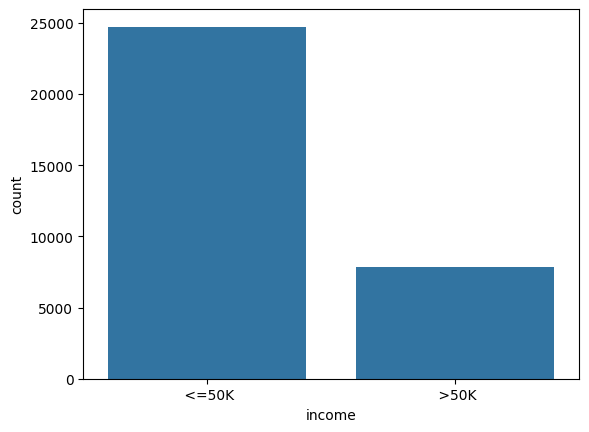

In [8]:
# visualização da distribuição da variável income
sns.countplot(x = df['income'])

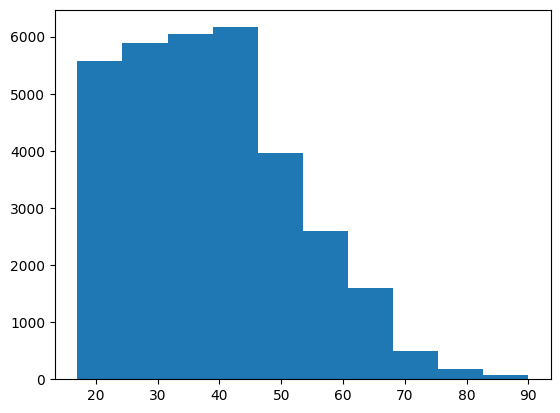

In [9]:
# visualização da distribuição da variável age
plt.hist(x = df['age']);

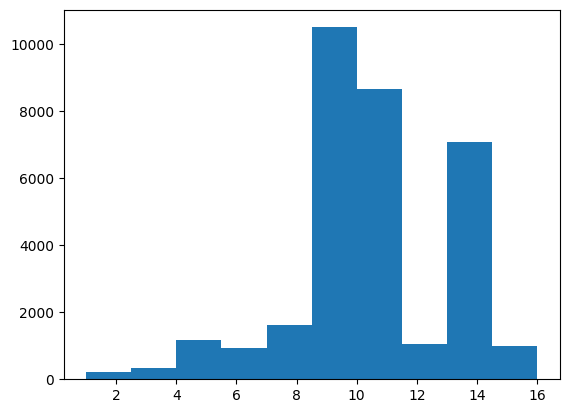

In [10]:
# visualização da distribuição da variável education-num
plt.hist(x = df['education-num']);

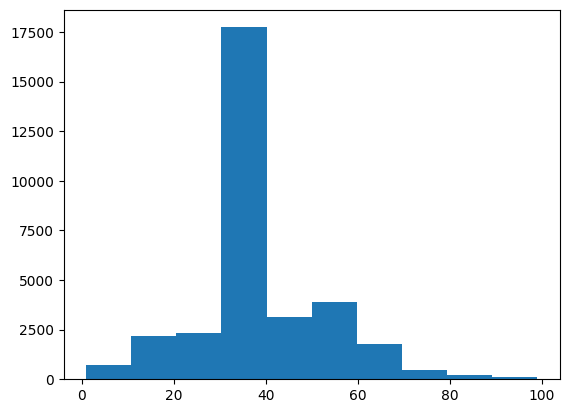

In [11]:
# visualização da distribuição da variável hour-per-week
plt.hist(x = df['hour-per-week']);

### Separação de Variáveis Preditoras e Variável Alvo

In [12]:
# separação das variáveis preditoras
x = df.iloc[:, 0:14].values

In [13]:
# separação da variável alvo
y = df.iloc[:, 14].values
y

array([' <=50K', ' <=50K', ' <=50K', ..., ' <=50K', ' <=50K', ' >50K'],
      shape=(32561,), dtype=object)

### Transformação de Variáveis Categóricas em Variáveis Numéricas

In [14]:
# transformação das variáveis categóricas em numéricas 
onehotencoder_census = ColumnTransformer(transformers=[('OneHot', OneHotEncoder(), [1, 3, 5, 6, 7, 8, 9, 13])], remainder='passthrough')
x = onehotencoder_census.fit_transform(x)
x.shape

(32561, 108)

### Separação de Dados de Treino e Teste

In [15]:
# separação de dados de treino e teste
x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.30, random_state=42)

### Criação e Treinamento do Modelo

In [16]:
# criação do modelo
modelo = DecisionTreeClassifier(  criterion='gini',
    max_depth=10,
    min_samples_leaf=10,
    random_state=42
)
modelo.fit(x_treino, y_treino)

DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, random_state=42)

In [17]:
# teste do modelo
previsoes = modelo.predict(x_teste)
print(previsoes)
print(y_teste)

[' <=50K' ' <=50K' ' >50K' ... ' <=50K' ' <=50K' ' >50K']
[' <=50K' ' <=50K' ' >50K' ... ' <=50K' ' >50K' ' >50K']


### Avaliação do Modelo

In [18]:
# acurácia
acuracia = accuracy_score(previsoes, y_teste)
acuracia 

0.8543351417750026

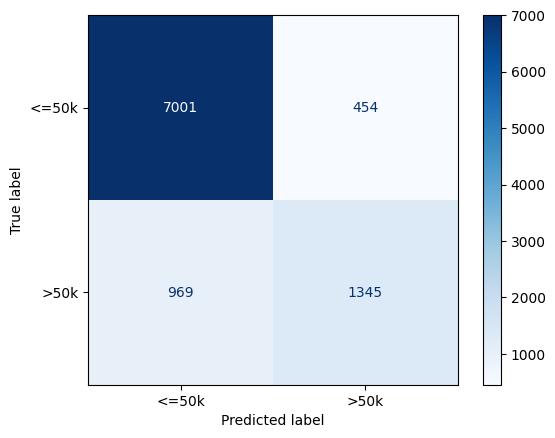

In [19]:
# visualização da matrix de confusão
cm = confusion_matrix(y_teste, previsoes)
cm_disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=50k', '>50k'])
cm_disp.plot(cmap='Blues')
plt.show()

In [20]:
# avaliação: precision, recall, f1-score e support
print(classification_report(y_teste, previsoes))

              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      7455
        >50K       0.75      0.58      0.65      2314

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.85      0.85      0.85      9769

